# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 38: A Intermitência do HHT Ajuda a Generalizar SMALL × MEDIUM?

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

**Pergunta.** No NB37, a única pista acústica que distingue Offshore Supply Ships (OSS, MEDIUM) de rebocadores (SMALL), independente do ganho, foi a **"intermitência" do HHT 2D** (coeficiente de variação da energia em passos de 80 ms). A Seção 6.1 do NB37 mostrou que ela mede sobretudo **energia relativa**: os OSS têm relativamente mais energia em ~100–200 Hz em relação ao componente dominante. O teste prático: juntar essa pista ao LOFAR melhora um classificador simples **em navios que ele nunca viu**?

**Desenho.**
- **Tarefas binárias:** OSS × Tug, e MEDIUM × SMALL (classes inteiras, subconjuntos A–D).
- **Atributos por gravação:** LOFAR médio até 4 kHz (512 faixas), intermitência do HHT 2D, os dois juntos e, como **controle**, o nível médio do psd24k (que depende do ganho do equipamento e, pelo NB37, é provavelmente instrumental).
- **Modelos:** regressão logística (PCA ajustado dentro de cada fold: 20 componentes do LOFAR e 10 da intermitência) e floresta aleatória.
- **Validação:** 5 partes agrupadas por navio (nenhum navio no treino e no teste), repetida com 10 sementes; os mesmos folds para todos os conjuntos de atributos, o que permite comparar par a par.
- **Peso:** cada navio pesa 1 no treino (peso 1/nº de gravações do navio). Sem isso, poucos navios com muitas gravações (os Motor Hoppers e os Pilot Vessels) dominam o ajuste.
- **Métrica principal:** AUC por navio (média das probabilidades das gravações de cada navio no teste). 0,5 = acaso.

**Cautela.** A intermitência foi escolhida olhando os mesmos navios OSS e Tug (NB37), então o resultado OSS × Tug é otimista para ela. Em MEDIUM × SMALL há muitos navios de outros tipos, o que torna esse teste mais independente.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 3); pd.set_option('display.width', 200)
PROC = os.path.join(R.ROOT, 'data', 'iara_processed')

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip(); meta['Length'] = pd.to_numeric(meta['Length'], errors='coerce')
meta = meta.set_index(meta.ID.astype(int)); meta = meta[meta.Dataset.isin(list('ABCD'))]

# atributos (caches criados pelos NB35 e NB37)
F = (np.arange(1024) + 1) * 16000 / 2048
LOF = pd.read_pickle(os.path.join(PROC, 'cache_lofar_espectro_medio.pkl')).loc[:, F <= 4000]
LOF.columns = [f'lofar_{i}' for i in range(LOF.shape[1])]
CV = pd.read_pickle(os.path.join(PROC, 'cache_hht_resumo.pkl'))['hht2d_cv'].copy()
CV.columns = [f'cv_{i}' for i in range(CV.shape[1])]
CV = CV.loc[:, CV.notna().mean() > 0.5]                   # faixas com intermitência definida na maioria das gravações
NV = pd.read_pickle(os.path.join(PROC, 'cache_psd24k_niveis.pkl'))[['nível médio']]
TAREFAS = {'OSS × Tug': ((meta['DETAILED TYPE'] == 'Offshore Supply Ship') & (meta.Length >= 50), (meta['DETAILED TYPE'] == 'Tug') & (meta.Length < 50)),
           'MEDIUM × SMALL': ((meta.Length >= 50) & (meta.Length < 100), meta.Length < 50)}
CONJ = {'LOFAR': ('l',), 'intermitência HHT': ('c',), 'LOFAR + intermitência': ('l', 'c'), 'nível (controle, depende do ganho)': ('n',)}
print(f'LOFAR: {LOF.shape[1]} faixas até 4 kHz; intermitência: {CV.shape[1]} faixas; nível: 1 valor')

LOFAR: 512 faixas até 4 kHz; intermitência: 126 faixas; nível: 1 valor


## 1. Experimento

Leva alguns minutos: 2 tarefas × 10 repetições × 2 pesos × 2 modelos × 4 conjuntos de atributos × 5 folds.

In [2]:
def pipe(partes, modelo):
    tr = []
    if 'l' in partes: tr.append(('l', make_pipeline(StandardScaler(), PCA(20, random_state=0)), list(LOF.columns)))
    if 'c' in partes: tr.append(('c', make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), PCA(10, random_state=0)), list(CV.columns)))
    if 'n' in partes: tr.append(('n', StandardScaler(), ['nível médio']))
    clf = (LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000) if modelo == 'logística' else
           RandomForestClassifier(300, min_samples_leaf=3, class_weight='balanced', random_state=0, n_jobs=-1))
    return make_pipeline(ColumnTransformer(tr), clf)

_rows = []
for tarefa, (ma, mb) in TAREFAS.items():
    ids = meta.index[ma | mb].intersection(LOF.index).intersection(CV.index).intersection(NV.index)
    y = pd.Series(ma[ids].astype(int).values, index=ids)
    X = LOF.loc[ids].join(CV.loc[ids]).join(NV.loc[ids])
    g = meta.loc[ids, 'Ship ID'].values
    print(f'{tarefa}: {len(ids)} gravações de {len(set(g))} navios ({int(y.sum())} gravações da 1ª classe)')
    for rep in range(10):
        folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=rep).split(X, y, g))
        for peso in ('1 por navio', 'sem peso'):
            for modelo in ('logística', 'floresta'):
                for nome, partes in CONJ.items():
                    pr = pd.Series(np.nan, index=ids)
                    for tr, te in folds:
                        m = pipe(partes, modelo)
                        kw = {}
                        if peso == '1 por navio':
                            gtr = pd.Series(g[tr]); kw = {m.steps[-1][0] + '__sample_weight': (1.0 / gtr.map(gtr.value_counts())).values}
                        m.fit(X.iloc[tr], y.iloc[tr], **kw)
                        pr.iloc[te] = m.predict_proba(X.iloc[te])[:, 1]
                    ps, ys = pr.groupby(g).mean(), y.groupby(g).first()
                    _rows.append({'tarefa': tarefa, 'peso': peso, 'modelo': modelo, 'atributos': nome, 'repetição': rep,
                                  'AUC por navio': roc_auc_score(ys, ps), 'acurácia balanceada por navio': balanced_accuracy_score(ys, ps > 0.5),
                                  'AUC por gravação': roc_auc_score(y, pr)})
RES = pd.DataFrame(_rows)

OSS × Tug: 226 gravações de 80 navios (139 gravações da 1ª classe)


MEDIUM × SMALL: 873 gravações de 169 navios (397 gravações da 1ª classe)


## 2. Resultados

Peso 1 por navio (principal); média e desvio entre as 10 repetições:


AUC por navio        acurácia balanceada por navio        AUC por gravação       
                                                                     mean    std                          mean    std             mean    std
tarefa         modelo    atributos                                                                                                           
MEDIUM × SMALL floresta  LOFAR                                      0.551  0.029                         0.528  0.033            0.580  0.029
                         LOFAR + intermitência                      0.592  0.037                         0.577  0.042            0.580  0.035
                         intermitência HHT                          0.575  0.036                         0.555  0.034            0.496  0.024
                         nível (controle, depende do ganho)         0.586  0.020                         0.550  0.025            0.488  0.009
               logística LOFAR                                      0.537  0.028                         0.533  0.023            0.533  0.021
                         LOFAR + intermitência                      0.590  0.027                         0.570  0.017            0.532  0.013
                         intermitência HHT                          0.579  0.015                         0.573  0.013            0.521  0.012
                         nível (controle, depende do ganho)         0.695  0.004                         0.663  0.006            0.519  0.004
OSS × Tug      floresta  LOFAR                                      0.681  0.031                         0.627  0.042            0.616  0.030
                         LOFAR + intermitência                      0.705  0.042                         0.635  0.023            0.621  0.030
                         intermitência HHT                          0.685  0.029                         0.614  0.031            0.609  0.030
                         nível (controle, depende do ganho)         0.751  0.027                         0.701  0.035            0.638  0.025
               logística LOFAR                                      0.657  0.048                         0.626  0.035            0.629  0.032
                         LOFAR + intermitência                      0.673  0.037                         0.641  0.034            0.602  0.032
                         intermitência HHT                          0.688  0.025                         0.634  0.026            0.586  0.029
                         nível (controle, depende do ganho)         0.762  0.005                         0.728  0.009            0.585  0.005

Ganho de AUC por navio ao juntar a intermitência ao LOFAR (mesmos folds):


ganho médio de AUC  desvio  % das repetições com ganho
tarefa         modelo                                                           
MEDIUM × SMALL floresta                0.041   0.028                       100.0
               logística               0.053   0.020                       100.0
OSS × Tug      floresta                0.024   0.030                        80.0
               logística               0.016   0.022                        70.0

AUC por navio, com e sem peso por navio:


peso                                                         1 por navio  sem peso
tarefa         modelo    atributos                                                
MEDIUM × SMALL floresta  LOFAR                                     0.551     0.569
                         LOFAR + intermitência                     0.592     0.599
                         intermitência HHT                         0.575     0.559
                         nível (controle, depende do ganho)        0.586     0.530
               logística LOFAR                                     0.537     0.542
                         LOFAR + intermitência                     0.590     0.578
                         intermitência HHT                         0.579     0.572
                         nível (controle, depende do ganho)        0.695     0.613
OSS × Tug      floresta  LOFAR                                     0.681     0.661
                         LOFAR + intermitência                     0.705     0.689
                         intermitência HHT                         0.685     0.680
                         nível (controle, depende do ganho)        0.751     0.771
               logística LOFAR                                     0.657     0.682
                         LOFAR + intermitência                     0.673     0.653
                         intermitência HHT                         0.688     0.599
                         nível (controle, depende do ganho)        0.762     0.756

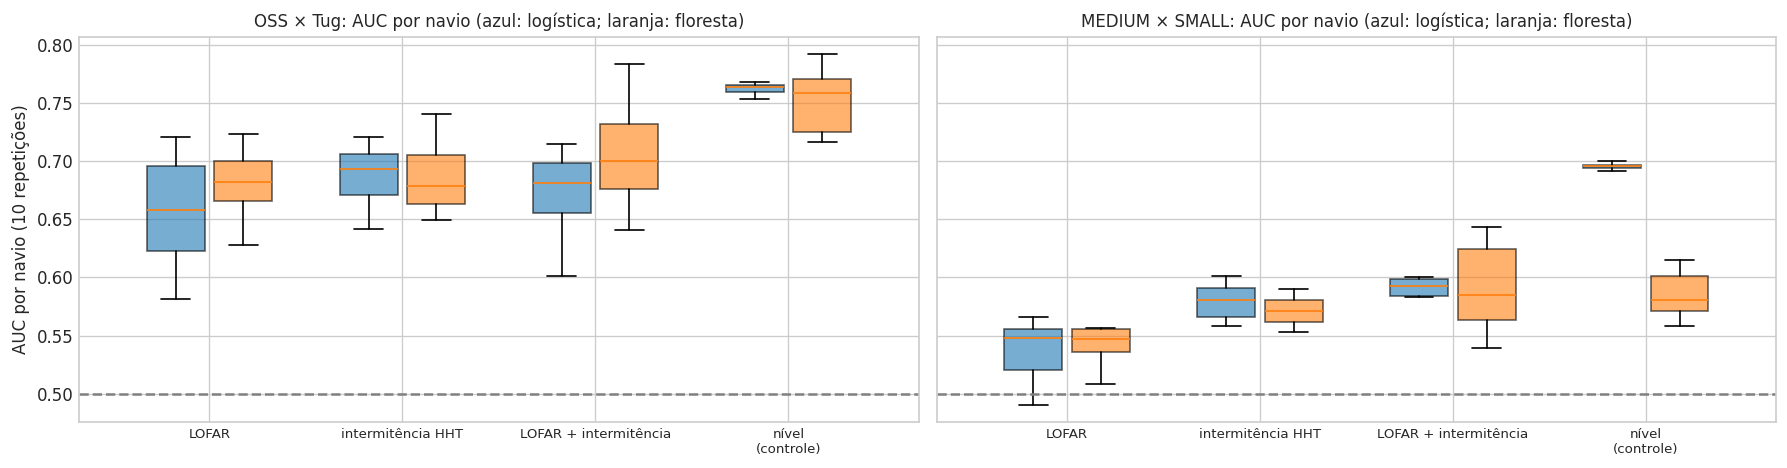

In [3]:
MET = ['AUC por navio', 'acurácia balanceada por navio', 'AUC por gravação']
PRINC = RES[RES.peso == '1 por navio'].groupby(['tarefa', 'modelo', 'atributos'])[MET].agg(['mean', 'std'])
print('Peso 1 por navio (principal); média e desvio entre as 10 repetições:'); display(PRINC.round(3))

_pv = RES[RES.peso == '1 por navio'].pivot_table(index=['tarefa', 'modelo', 'repetição'], columns='atributos', values='AUC por navio')
GANHO = (_pv['LOFAR + intermitência'] - _pv['LOFAR']).groupby(level=[0, 1]).agg(
    ganho_medio='mean', desvio='std', repeticoes_com_ganho=lambda x: 100 * (x > 0).mean())
GANHO.columns = ['ganho médio de AUC', 'desvio', '% das repetições com ganho']
print('Ganho de AUC por navio ao juntar a intermitência ao LOFAR (mesmos folds):'); display(GANHO.round(3))

SEMPESO = RES.groupby(['tarefa', 'modelo', 'atributos', 'peso'])['AUC por navio'].mean().unstack('peso')
print('AUC por navio, com e sem peso por navio:'); display(SEMPESO.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a_, t in zip(ax, TAREFAS):
    d = RES[(RES.tarefa == t) & (RES.peso == '1 por navio')]
    nomes = list(CONJ)
    for k, mod in enumerate(('logística', 'floresta')):
        vals = [d[(d.modelo == mod) & (d.atributos == n)]['AUC por navio'].values for n in nomes]
        pos = np.arange(len(nomes)) + (k - 0.5) * 0.35
        bp = a_.boxplot(vals, positions=pos, widths=0.3, patch_artist=True, showfliers=False)
        for b in bp['boxes']:
            b.set_facecolor('tab:blue' if mod == 'logística' else 'tab:orange'); b.set_alpha(0.6)
    a_.axhline(0.5, color='gray', ls='--'); a_.set_xticks(range(len(nomes))); a_.set_xticklabels([n.replace(' (controle, depende do ganho)', '\n(controle)') for n in nomes], fontsize=8)
    a_.set_title(f'{t}: AUC por navio (azul: logística; laranja: floresta)', fontsize=10)
ax[0].set_ylabel('AUC por navio (10 repetições)')
plt.tight_layout(); plt.show()

**Leitura.**
- **OSS × Tug (AUC por navio):** logística: LOFAR 0,66, intermitência 0,69, juntos 0,67, nível (controle) 0,76; floresta: LOFAR 0,68, intermitência 0,68, juntos 0,70, nível (controle) 0,75. Ganho ao juntar a intermitência ao LOFAR: logística: +0,016 (ganho em 70% das repetições); floresta: +0,024 (ganho em 80% das repetições).
- **MEDIUM × SMALL (AUC por navio):** logística: LOFAR 0,54, intermitência 0,58, juntos 0,59, nível (controle) 0,69; floresta: LOFAR 0,55, intermitência 0,57, juntos 0,59, nível (controle) 0,59. Ganho ao juntar a intermitência ao LOFAR: logística: +0,053 (ganho em 100% das repetições); floresta: +0,041 (ganho em 100% das repetições).
- **O LOFAR sozinho quase não separa MEDIUM de SMALL em navios novos** (AUC 0,54 na logística e 0,55 na floresta), coerente com o NB29 e o NB35. A intermitência traz um ganho pequeno e consistente (positivo em todas as combinações), mas o melhor resultado em MEDIUM × SMALL fica em AUC 0,59 e acurácia balanceada 0,58: pouco acima do acaso.
- **OSS × Tug chega a AUC ~0,70** em navios novos, mesmo com o LOFAR sozinho, que no NB37 não mostrava nenhuma faixa diferente: combinando muitas faixas fracas, o classificador acha alguma separação. Mas o **controle de nível**, que não é acústico, dá AUC parecida ou maior: uma AUC de ~0,7 nessa comparação não basta para afirmar que o modelo aprendeu o som do navio.
- **Peso por navio:** sem ele, os resultados mudam bastante (por exemplo, o controle de nível em MEDIUM × SMALL com a logística vai de 0,69 com peso para 0,61 sem peso), porque poucos navios muito gravados dominam o ajuste e o que vale para eles não vale para os outros.

## 3. Conclusões

1. **A intermitência do HHT (na prática, a energia relativa das faixas no HHT 2D) ajuda pouco.** Juntá-la ao LOFAR aumenta a AUC por navio em logística: +0,053 (ganho em 100% das repetições); floresta: +0,041 (ganho em 100% das repetições) em MEDIUM × SMALL, mas o resultado continua perto do acaso (melhor AUC 0,59). Ela não resolve a generalização de MEDIUM.
2. **SMALL × MEDIUM continua sem solução acústica nestes dados.** Nenhuma combinação testada separa as duas classes em navios novos de forma útil; isso confirma, agora com um classificador, o que os NB35–37 mostraram faixa a faixa.
3. **Separações de AUC ~0,7 precisam de controle.** No par OSS × Tug, uma variável sabidamente instrumental (o nível sem calibração) separa tão bem quanto as acústicas. Qualquer resultado nesse patamar pode vir das condições de gravação, e não do navio.
4. **Para o artigo e a dissertação:** o recall de MEDIUM relatado com o split por gravação (~60%) vem sobretudo do reconhecimento de navios repetidos; com navios novos, nem o LOFAR, nem o MEL, nem o DEMON, nem o HHT, nem a combinação com a intermitência levam a uma classificação útil de MEDIUM.